(19735, 29)
0 missing, 0 duplikat
               count                 mean                  min  \
date           19735  2016-03-20 05:30:00  2016-01-11 17:00:00   
Appliances   19735.0            97.694958                 10.0   
lights       19735.0             3.801875                  0.0   
T1           19735.0            21.686571                16.79   
RH_1         19735.0            40.259739            27.023333   
T2           19735.0            20.341219                 16.1   
RH_2         19735.0             40.42042            20.463333   
T3           19735.0            22.267611                 17.2   
RH_3         19735.0              39.2425            28.766667   
T4           19735.0            20.855335                 15.1   
RH_4         19735.0            39.026904                27.66   
T5           19735.0            19.592106                15.33   
RH_5         19735.0            50.949283               29.815   
T6           19735.0             7.910939 

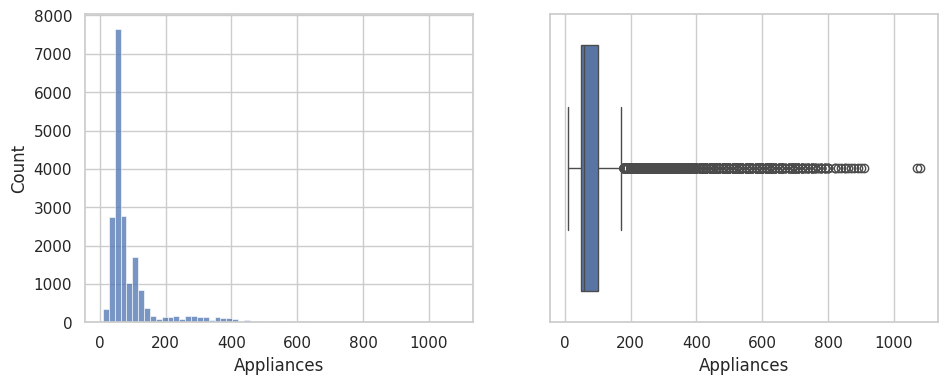

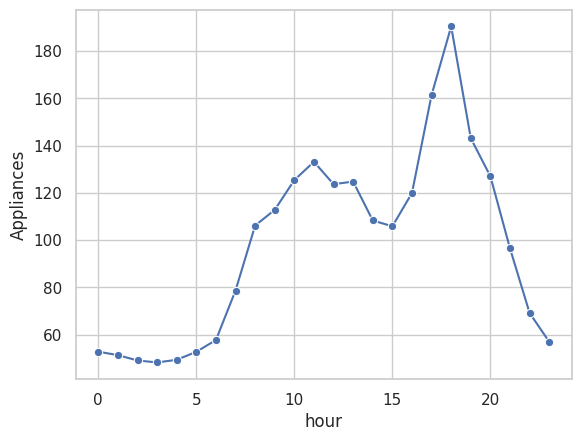

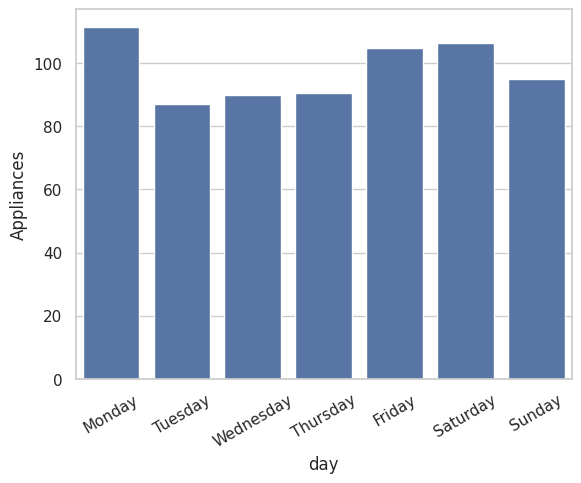

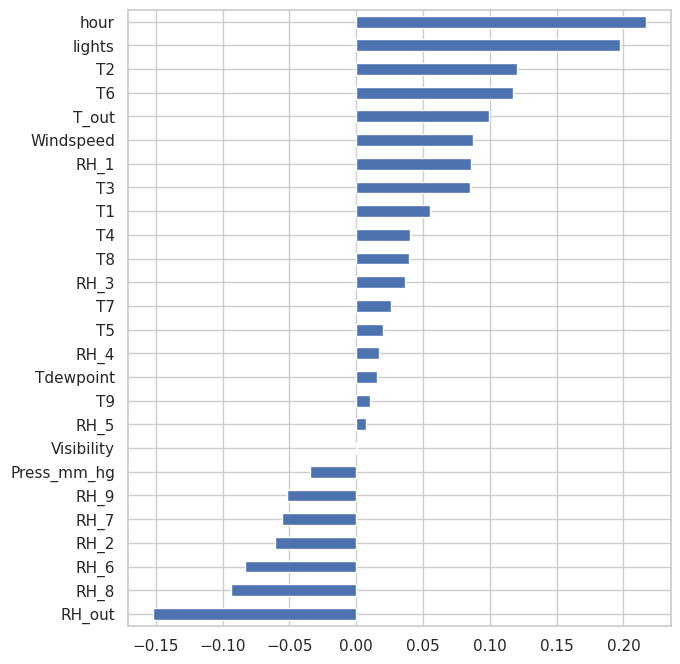

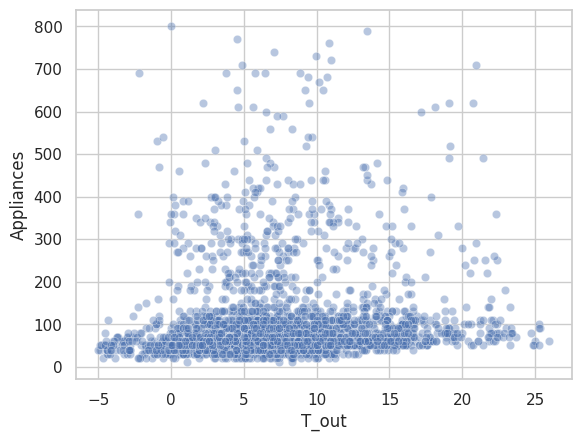

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("energydata_complete.csv", parse_dates=["date"])

# cek dasar
print(df.shape)
print(df.isna().sum().sum(), "missing,", df.duplicated().sum(), "duplikat")
print(df.describe().T)

# fitur waktu
df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.day_name()

# 1. distribusi
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Appliances"], bins=60, ax=ax[0])
sns.boxplot(x=df["Appliances"], ax=ax[1])
plt.show()

# 2. pola per jam
sns.lineplot(data=df, x="hour", y="Appliances", errorbar=None, marker="o")
plt.show()

# 3. pola per hari
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
sns.barplot(data=df, x="day", y="Appliances", order=order, errorbar=None)
plt.xticks(rotation=30)
plt.show()

# 4. korelasi
corr = df.drop(columns=["date","day","rv1","rv2"]).corr()["Appliances"].drop("Appliances").sort_values()
corr.plot(kind="barh", figsize=(7, 8))
plt.show()

# 5. suhu luar vs konsumsi
sns.scatterplot(data=df.sample(3000, random_state=1), x="T_out", y="Appliances", alpha=0.4)
plt.show()

# Kapan Rumah Paling Boros Listrik? Eksplorasi Data Sensor IoT dengan Python

*Eksplorasi data konsumsi energi peralatan rumah tangga dari 19.735 pembacaan sensor selama ±4,5 bulan.*

## Pendahuluan
Sebagai mahasiswa Teknik Komputer, saya tertarik pada data yang dihasilkan sensor IoT. Pada tulisan ini saya mengeksplorasi dataset **Appliances Energy Prediction** (UCI Machine Learning Repository) untuk menjawab: **kapan dan mengapa konsumsi listrik peralatan rumah meningkat?**

## Tentang Dataset
- 19.735 baris, 29 kolom, dicatat setiap 10 menit (11 Jan - 27 Mei 2016)
- Target: `Appliances` (konsumsi energi peralatan, Wh)
- Fitur: suhu (T1-T9) dan kelembapan (RH_1-RH_9) di berbagai ruangan, kondisi cuaca luar, dan `lights`
- Kualitas data: tidak ada missing value dan tidak ada duplikat

## Langkah Eksplorasi
(sisipkan kode dari notebook, lalu gambar di bawah)

### 1. Distribusi konsumsi
![distribusi](gambar/1_distribusi.png)
Rata-rata konsumsi 97,7 Wh, tetapi median hanya 60 Wh. Distribusinya miring ke kanan (skewness ≈ 3,4) dan sekitar 10,8% data adalah outlier (di atas 175 Wh). Artinya rumah ini biasanya hemat, dengan lonjakan sesekali.

### 2. Pola per jam
![per jam](gambar/2_per_jam.png)
Konsumsi terendah dini hari (sekitar 48 Wh pada pukul 03.00), naik tajam mulai pagi, dan **puncaknya pukul 18.00 (sekitar 190 Wh)**, hampir 4 kali lipat dari titik terendah.

### 3. Pola per hari
![per hari](gambar/3_per_hari.png)
Hari terboros adalah Senin (111,5 Wh) dan Sabtu (106,2 Wh), sedangkan Selasa paling hemat (87,1 Wh). Perbedaannya tidak besar sehingga pola harian lebih berpengaruh daripada pola mingguan.

### 4. Korelasi antar fitur
![korelasi](gambar/4_korelasi.png)
Korelasi terkuat justru lemah: jam (0,22), `lights` (0,20), suhu T2 dan T6 (sekitar 0,12), dan kelembapan luar (-0,15). Tidak ada satu sensor pun yang menjelaskan konsumsi secara dominan.

### 5. Suhu luar vs konsumsi
![suhu luar](gambar/5_suhu_luar.png)
Hubungannya sangat lemah (r ≈ 0,10).

## Temuan Utama
1. Waktu dalam sehari adalah faktor terkuat, dengan puncak di sore hari.
2. Pemakaian lampu berkaitan dengan konsumsi, dan 77% waktu lampu mati.
3. Hubungan linear antar fitur lemah, jadi prediksi akurat kemungkinan butuh model non-linear (misalnya Random Forest).
4. Kolom `rv1` dan `rv2` identik (korelasi 1,0) dan merupakan variabel acak, sehingga sebaiknya dibuang.

## Kesimpulan & Langkah Lanjutan
Rumah ini paling boros pada jam pulang kerja. Langkah berikutnya: membuat fitur waktu tambahan, melatih model regresi, dan membandingkan performanya.

## Referensi
Candanedo, L.M., Feldheim, V., Deramaix, D. (2017). *Data driven prediction models of energy use of appliances in a low-energy house*. Energy and Buildings. Dataset: UCI Machine Learning Repository.

*Kode lengkap: [link GitHub kamu]*

In [16]:
import os
print(os.path.getsize("energydata_complete.csv"))

11979363
